# 07 TMSPa alone - rev01 - where does its water come from?

|                     |     |
| ------------------- | --- |
| **Status**          | Draft, 2026-10-29. Nothing is fitted |
| **Source**          | Y. Alcaraz Galván; NMR data from experiments (2023-05-15 and 2023-05-25); Gogoi et al., J. Phys. Chem. C 2024, 128, 1654 |
| **Scope**           | Why the model needs 65.6 mM of water in a tube with no water added, and what the spectra of that tube say against it |
| **Builds on**       | `05_fitting_rev08_(M1_steps)` §1.2 and S3 (the 65.6 mM) · [reference-fit_results.md](../docs/reference-fit_results.md) §6.3.7 (the decision) |
| **See also**        | [theory-reaction_mechanism.md](../docs/theory-reaction_mechanism.md) §3 (what the paper says of pure TMSPa) |

In [1]:
import sys
from pathlib import Path

REPO = Path.cwd() if (Path.cwd() / 'kinetics').is_dir() else Path.cwd().parent
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from demo import style
from kinetics.data import load_lab_observables
from kinetics.data.lab_nmr import build_lab_nmr_inventory, calculate_area_shares, calculate_window_integrals, load_spectrum
from kinetics.data.network import format_equation, get_active_network
from kinetics.data.observables import P_WINDOWS_PPM, load_lab_sample_folders
from kinetics.fitting.config import apply_fit_config
from kinetics.fitting.reporting import P_REGION_PPM
from kinetics.paths import lab_nmr_dir
from kinetics.reactor.protocol import DEFAULT_DENSITY_G_ML
from kinetics.thermo.reaction import calculate_network_thermo
from kinetics.thermo.uncertainty import calculate_solvation_covariance

style.apply_style()
apply_fit_config(REPO / 'notebooks' / 'results' / 'fit8_M1-steps_S1-tube')   # the network and samples of rev08

TUBE = 'TMSPa alone'
observables = load_lab_observables()
sample = observables['samples'][TUBE]
INVENTORY = build_lab_nmr_inventory(lab_nmr_dir()).drop_duplicates('data_md5')
folders = load_lab_sample_folders()
FILES = INVENTORY[INVENTORY['folder'].isin(folders['raw_sample_folders'][TUBE] + folders.get('raw_check_folders', {}).get(TUBE, []))]
C_TMSPA = sample['c0_M']['TMSPA']                   # M, from the recipe (5 vol%)
SILYL_ON_P = {'TMSPA': 3, 'BMSPA': 2, 'MMSPA': 1, 'H3PO4': 0}
# ¹H windows of rev08 S2: silyl on phosphate and free silyl (TMSOH −0.245, HMDSO −0.234 ppm)
H1_WINDOWS = {'P-bound silyl': (-0.100, 0.060), 'free silyl': (-0.300, -0.150)}
DAY = {0: 'day 0 (15 May)', 1: 'day 10 (25 May)'}
FILES[['folder', 'file', 'nucleus', 'acquired_at']].sort_values('acquired_at').reset_index(drop=True)

,folder,file,nucleus,acquired_at
0,5v%TMSPa in EDEC,NG230515_5v% TMSPa in EC_DEC_Proton-1-2.jdf,1H,2023-05-15 10:03:14
1,5v%TMSPa in EDEC,NG230515_5v% TMSPa in EC_DEC_31P-1-2.jdf,31P,2023-05-15 10:06:22
2,5v%TMSPa in EDEC,NG230515_5v% TMSPa in EC_DEC_29Si-1-2.jdf,29Si,2023-05-15 10:09:39
3,5v%TMSPa in EDEC,NG230515_5v% TMSPa in EC_DEC_29Si-2-2.jdf,29Si,2023-05-15 12:59:49
4,5v%TMSPa in EDEC,NG230515_5v% TMSPa in EC_DEC_29Si-3-2.jdf,29Si,2023-05-15 13:10:45
5,5v%TMSPa in EDEC,NG230515_5v% TMSPa in EC_DEC_29Si-4-2.jdf,29Si,2023-05-15 17:58:16
6,NG230525_5v%TMSPa in EC_DEC_AFTER 10 DAYS,NG230525_5v%TMSPa in EC_DEC_Proton-1-2.jdf,1H,2023-05-25 12:53:37
7,NG230525_5v%TMSPa in EC_DEC_AFTER 10 DAYS,NG230525_5v%TMSPa in EC_DEC_31P-1-2.jdf,31P,2023-05-25 12:55:55


- **The tube:** 5 vol% TMSPA (149 mM) in EC/DEC, nothing added. Two ³¹P and two ¹H spectra, 10 days apart; four ²⁹Si on day 0 only (noise, rev08 §2); no ¹³C.

---
## 1. What changed in 10 days? (³¹P)

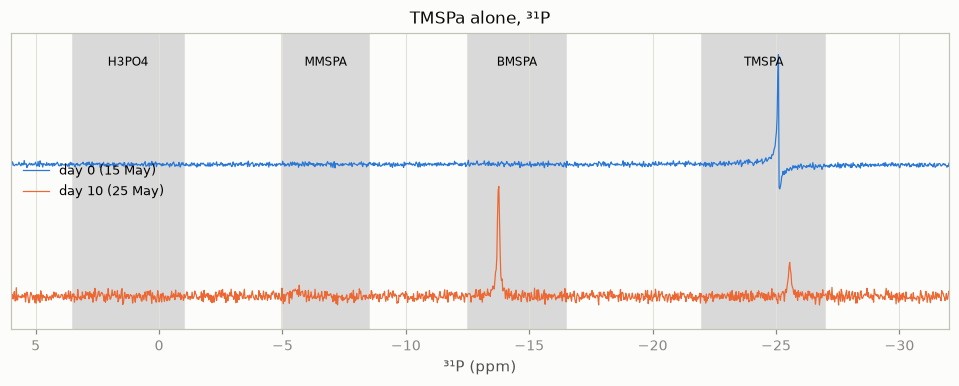

,day 0 (15 May),day 10 (25 May)
share of P,,
TMSPA,0.807,0.232
BMSPA,0.118,0.688
MMSPA,0.050,0.042
H3PO4,0.036,0.034


In [2]:
fig, ax = plt.subplots(figsize=(11, 3.5))
p31 = FILES[FILES['nucleus'] == '31P'].sort_values('acquired_at').reset_index(drop=True)
for i, row in p31.iterrows():
    ppm, y = load_spectrum(row['path'])
    ax.plot(ppm, y / y.max() + 1.2 * (1 - i), lw=0.8, label=DAY[i])
for name, (low, high) in P_WINDOWS_PPM.items():
    ax.axvspan(low, high, color='0.85', zorder=0)
    ax.text((low + high) / 2, 2.1, name, ha='center', fontsize=8)
ax.set_xlim(P_REGION_PPM[1], P_REGION_PPM[0])
ax.set_ylim(-0.3, 2.4); ax.set_xlabel('³¹P (ppm)'); ax.set_yticks([]); ax.legend(loc='center left')
ax.set_title('TMSPa alone, ³¹P')
plt.show()

shares = pd.DataFrame({DAY[i]: {sp: v['share'] for sp, v in s['shares'].items()} for i, s in enumerate(sample['spectra'])}).round(3)
display(shares.rename_axis('share of P'))

- **Day 0:** one line, TMSPA. The 0.12, 0.05 and 0.04 of the other windows are baseline, not lines.
- **Day 10:** most of the TMSPA is now one line at −13.7 ppm, read as BMSPA (TMSPA with one silyl group gone).
- **Nothing else:** no line outside the four windows above the noise (no new phosphate).

## 2. How much water does that need?

silyl groups gone at day 10: 0.874 per P = 131 mM
least water that gives them (all as HMDSO): 65.3 mM = 1034 ppm


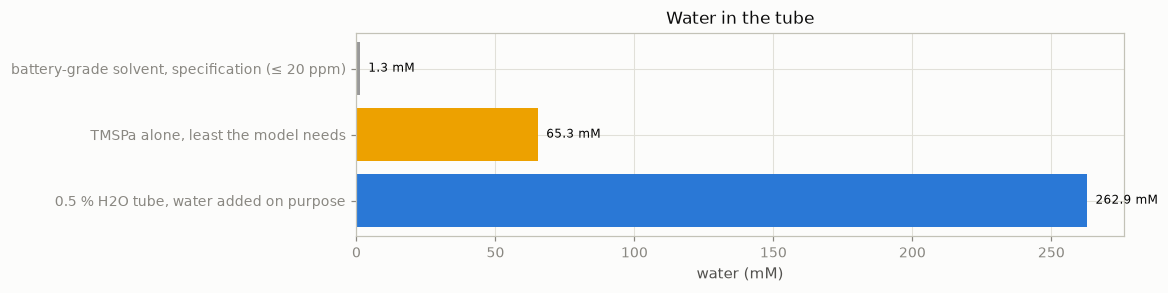

In [3]:
last = {sp: v['share'] for sp, v in sample['spectra'][-1]['shares'].items()}
silyl_lost = sum((3 - n) * last[sp] for sp, n in SILYL_ON_P.items())           # per P
silyl_lost_M = silyl_lost * C_TMSPA
water_min_M = silyl_lost_M / 2       # cheapest case: every lost silyl ends in HMDSO (2 silyl per O)

# mM → ppm by mass. Density of the mixture: EC/DEC 1:1 by volume with 5 vol% TMSPA; DEC 0.975 g/mL (DECLARED)
density = 0.95 * (0.5 * DEFAULT_DENSITY_G_ML['EC'] + 0.5 * 0.975) + 0.05 * DEFAULT_DENSITY_G_ML['TMSPA']
to_ppm = lambda c_M: c_M * 18.015 / (1000 * density) * 1e6
print(f'silyl groups gone at day 10: {silyl_lost:.3f} per P = {1e3 * silyl_lost_M:.0f} mM')
print(f'least water that gives them (all as HMDSO): {1e3 * water_min_M:.1f} mM = {to_ppm(water_min_M):.0f} ppm')

water = pd.Series({'battery-grade solvent, specification (≤ 20 ppm)': 20 / to_ppm(1) * 1e3,
                   'TMSPa alone, least the model needs': 1e3 * water_min_M,
                   '0.5 % H2O tube, water added on purpose': 1e3 * observables['samples']['0.5 % H2O']['c0_M']['H2O']})
fig, ax = plt.subplots(figsize=(9, 2.4))
ax.barh(water.index, water.values, color=['0.6', 'C3', 'C0'])
for y, v in enumerate(water.values):
    ax.text(v + 3, y, f'{v:.1f} mM', va='center', fontsize=8)
ax.invert_yaxis(); ax.set_xlabel('water (mM)'); ax.set_title('Water in the tube')
plt.show()

- **These shares give 65.3 mM; rev08 declares 65.6 mM** (the same balance). Either way:
- **65 mM is not a trace.** It is about 1000 ppm, 50 times a dry battery solvent, and a quarter of the water put into the 0.5 % tube on purpose.
- The paper only says TMSPa is "very sensitive toward impurities, even if those impurities are present in very low amounts", and that pure TMSPa already shows some BMSPA (theory doc §3.1). Very low amounts, not 1000 ppm.

## 3. Did the silyl groups really leave the phosphate? (¹H)

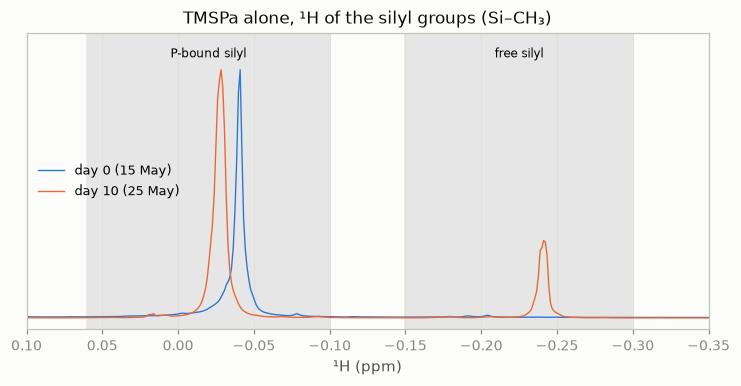

,day 0 (15 May),day 10 (25 May)
share of silyl,,
P-bound silyl,0.98,0.792
free silyl,0.02,0.208
free silyl (mM),9.10,93.267


In [4]:
fig, ax = plt.subplots(figsize=(8, 3.5))
h1 = FILES[FILES['nucleus'] == '1H'].sort_values('acquired_at').reset_index(drop=True)
h1_shares = {}
for i, row in h1.iterrows():
    ppm, y = load_spectrum(row['path'])
    inside = (ppm > -0.35) & (ppm < 0.10)
    ax.plot(ppm[inside], y[inside] / y[inside].max(), lw=0.9, label=DAY[i])
    h1_shares[DAY[i]] = calculate_area_shares(ppm, y, H1_WINDOWS, region_ppm=(-0.6, 0.4))['share']
for name, (low, high) in H1_WINDOWS.items():
    ax.axvspan(low, high, color='0.9', zorder=0)
    ax.text((low + high) / 2, 1.05, name, ha='center', fontsize=8)
ax.set_xlim(0.10, -0.35); ax.set_ylim(-0.05, 1.15)
ax.set_xlabel('¹H (ppm)'); ax.set_yticks([]); ax.legend(loc='center left')
ax.set_title('TMSPa alone, ¹H of the silyl groups (Si–CH₃)')
plt.show()

h1_shares = pd.DataFrame(h1_shares)
h1_shares.loc['free silyl (mM)'] = h1_shares.loc['free silyl'] * 3 * 1e3 * C_TMSPA
display(h1_shares.round(3).rename_axis('share of silyl'))

- United to P: TMSPa, BMSPa and MMSPA
- Free silyl: TMSOH, HDMSO (and TMSOEG and TMSOdiEG)

- **Yes.** On day 10 a free silyl line appears at −0.24 ppm (TMSOH −0.245, HMDSO −0.234). It holds about 93 mM of silyl groups; ³¹P says 131 mM. Two nuclei, read separately, agree that silyl left the phosphate.
- So the question is not *whether* silyl left, but **where the oxygen that took it came from**.

## 4. Why does the model say "water"?

,reaction,family,silyl off P,water used,ΔG_rxn (eV),σ_solv (eV)
step,,,,,,
R1,TMSPA + H2O ⇌ BMSPA + TMSOH,hydrolysis,1,1,-0.253,0.104
R2,BMSPA + H2O ⇌ MMSPA + TMSOH,hydrolysis,1,1,-0.182,0.094
R3,MMSPA + H2O ⇌ H3PO4 + TMSOH,hydrolysis,1,1,-0.061,0.081
R4,2 TMSOH ⇌ HMDSO + H2O,condensation,0,-1,+0.097,0.120
R5,TMSPA + TMSOH ⇌ BMSPA + HMDSO,transfer,1,0,-0.155,0.111
R6,BMSPA + TMSOH ⇌ MMSPA + HMDSO,transfer,1,0,-0.085,0.102
R7,MMSPA + TMSOH ⇌ H3PO4 + HMDSO,transfer,1,0,+0.036,0.090
R8,EC + TMSOH ⇌ TMSOEG + CO2,solvent_attack,0,0,+0.113,0.103
R9,EC + TMSOEG ⇌ TMSOdiEG + CO2,solvent_attack,0,0,-0.016,0.106


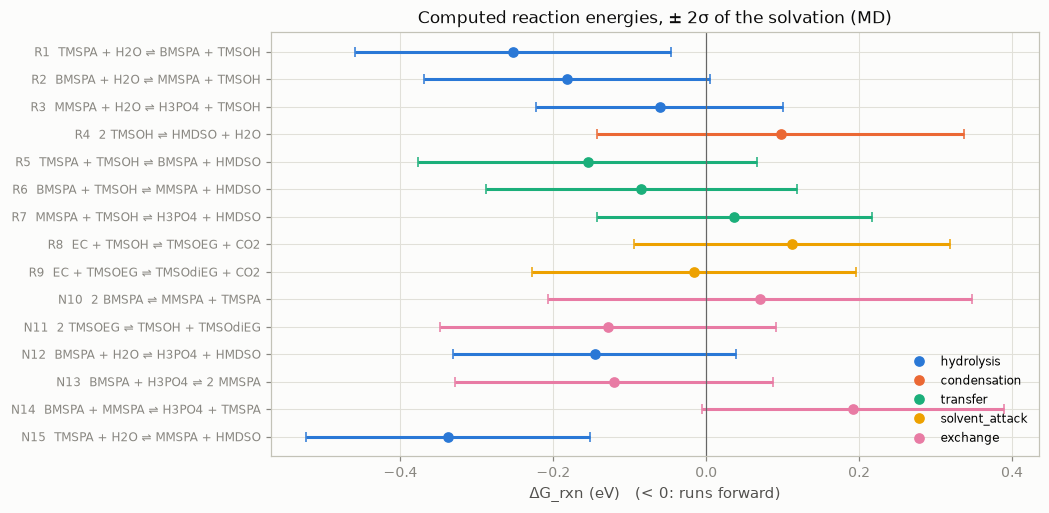

In [5]:
# ΔG_rxn = gas phase (DFT) + solvation (MD, EC/DEC); σ is the standard error of the solvation part only (MD), no DFT error
network = get_active_network()
thermo = calculate_network_thermo(298.15, network=network)      # one row per reaction
rows = []
for name, rxn in network.items():
    side = lambda key: sum(n * SILYL_ON_P.get(sp, 0) for sp, n in rxn[key].items())
    d_silyl = side('products') - side('reactants')
    d_water = rxn['products'].get('H2O', 0) - rxn['reactants'].get('H2O', 0)
    rows.append({'step': name, 'reaction': format_equation(rxn), 'family': rxn['class'],
                 'silyl off P': -d_silyl, 'water used': -d_water,
                 'ΔG_rxn (eV)': thermo.loc[name, 'dG_rxn_eV'], 'σ_solv (eV)': thermo.loc[name, 'sigma_solv_eV']})
steps = pd.DataFrame(rows).set_index('step')
display(steps.style.format({'ΔG_rxn (eV)': '{:+.3f}', 'σ_solv (eV)': '{:.3f}'}))

fig, ax = plt.subplots(figsize=(9, 5))
families = list(dict.fromkeys(steps['family']))
for y, (name, row) in enumerate(steps.iterrows()):
    color = f'C{families.index(row["family"])}'
    ax.errorbar(row['ΔG_rxn (eV)'], y, xerr=2 * row['σ_solv (eV)'], fmt='o', color=color, capsize=3)
ax.axvline(0, color='0.4', lw=0.8)
ax.set_yticks(range(len(steps)), [f'{name}  {row["reaction"]}' for name, row in steps.iterrows()], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel('ΔG_rxn (eV)   (< 0: runs forward)')
ax.set_title('Computed reaction energies, ± 2σ of the solvation (MD)')
ax.legend(handles=[plt.Line2D([], [], marker='o', ls='', color=f'C{i}', label=f) for i, f in enumerate(families)], fontsize=8, loc='lower right')
plt.show()

- T,B,MMSPa can conly form with H2O and TMSOH
- TMSOH can form itself, so: 
    - We have TMSOH contamination
    - We have H2O contamination
    - We miss reactions

- Every step that takes silyl off phosphorus uses **water** (hydrolysis) or **TMSOH** (transfer), and TMSOH only comes from water. The exchanges only move silyl from one phosphate to another.
- **No step lets silyl leave without water.** So the model must invent water, and 65 mM is what the network asks for, not what the tube holds.

### 4.1 Can a trace of water recycle itself?

The idea: a little water makes TMSOH (R1), two TMSOH give the water back (R4), and the cycle runs again.

In [6]:
# Two hydrolyses (R1) and one condensation (R4): what the cycle does in net
cycle = {'R1': 2, 'R4': 1}
net = {}
for name, n in cycle.items():
    for key, sign in (('reactants', -1), ('products', 1)):
        for sp, k in network[name][key].items():
            net[sp] = net.get(sp, 0) + sign * n * k
net = {sp: k for sp, k in net.items() if k}
w = pd.Series(cycle, dtype=float)
cov = calculate_solvation_covariance(list(cycle), network=network)
dG = float((w * thermo.loc[w.index, 'dG_rxn_eV']).sum())
sigma = float(np.sqrt(w @ cov.loc[w.index, w.index].values @ w))
print('net: ' + ' + '.join(f'{-k} {sp}' for sp, k in net.items() if k < 0) + ' → ' + ' + '.join(f'{k} {sp}' for sp, k in net.items() if k > 0))
print(f'ΔG = {dG:+.3f} ± {2 * sigma:.3f} eV (2σ)')

net: 2 TMSPA + 1 H2O → 2 BMSPA + 1 HMDSO
ΔG = -0.408 ± 0.356 eV (2σ)


- **The water comes back only half.** Per cycle two silyl groups leave phosphorus and one water is still used: the oxygen of HMDSO (TMS–O–TMS) has to come from somewhere.
- **This cycle is already the 65 mM.** The minimum of §2 assumes every lost silyl ends as HMDSO, the case where R4 gives back all the water it can. Trace water cannot do more than this inside the network.
- So a trace (≈ 1 mM) gives at most ≈ 2 mM of silyl lost, not 131 mM. To go further an oxygen must come from outside the network: water from outside, or a reaction the network lacks.
- **And R4 runs backwards in the computed energies** (ΔG = +0.10 eV, figure of §4; its 2σ reaches −0.14): alone, TMSOH does not give its water back. The cycle runs only because R1 pulls it (net ΔG −0.41 ± 0.36 eV, 2σ).

## 5. Where could we be wrong?

| | Hypothesis | What it predicts | What these spectra show |
|---|---|---|---|
| 1 | **A step without water is missing**: P–O–Si + Si–O–P → P–O–P + HMDSO (silyl pyrophosphates), or silyl exchange with the solvent (P–OEt + TMS–O–C(O)OEt from DEC) | new ³¹P lines (P–O–P, ethyl phosphates); new ethyl lines in ¹H | ³¹P: no new line (§1). ¹H: new ethyl lines, but in every tube of that day, phosphate or not (§5.1) |
| 2 | **The −13.7 ppm line is not BMSPA** (an ethyl or P–O–P species at the same place) | the 131 mM of silyl lost changes | the BMSPA line moves with water (−13.9 to −15.2 ppm, paper), so its place alone does not decide. The ³¹P is ¹H-decoupled: no P–H coupling to tell P–OEt |
| 3 | **The tube was wet** (solvent, air while preparing, the cap) | ≈ 1000 ppm by Karl Fischer | not measured |

### 5.1 The new ethyl lines in ¹H are not from TMSPa

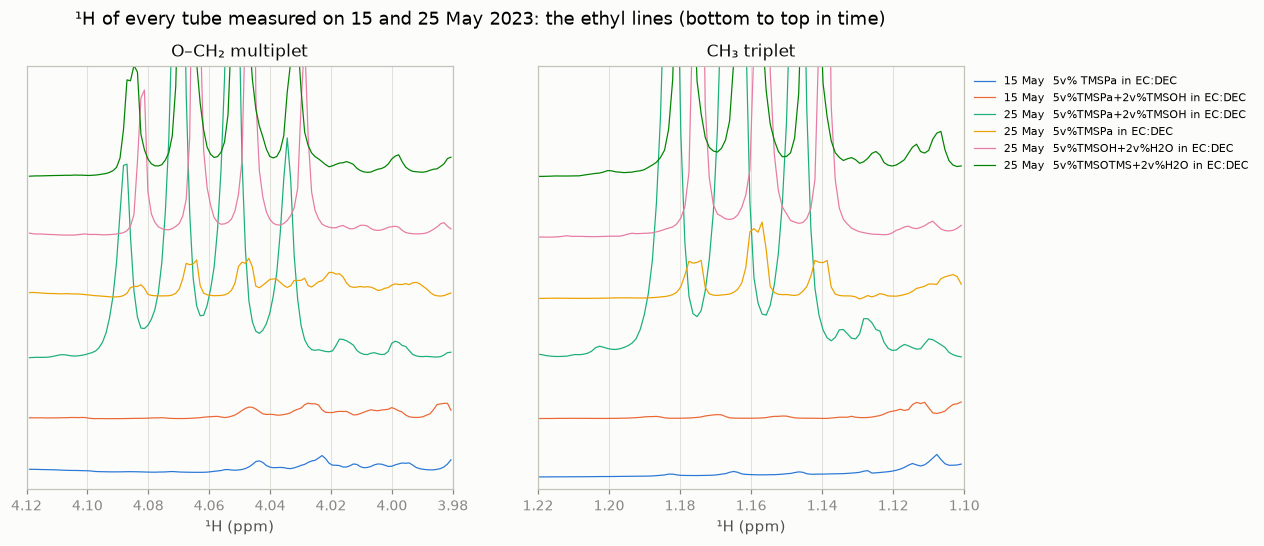

,triplet / DEC CH3 (‰),triplet at (ppm)
15 May 5v% TMSPa in EC:DEC,1.374,1.165
15 May 5v%TMSPa+2v%TMSOH in EC:DEC,-0.306,1.169
25 May 5v%TMSPa+2v%TMSOH in EC:DEC,254.288,1.165
25 May 5v%TMSPa in EC:DEC,16.591,1.157
25 May 5v%TMSOH+2v%H2O in EC:DEC,177.655,1.157
25 May 5v%TMSOTMS+2v%H2O in EC:DEC,132.422,1.159


In [7]:
ETHYL = {'triplet 1.16': (1.135, 1.185), 'multiplet 4.05': (4.02, 4.09), 'DEC CH3': (0.85, 1.05)}
day_rows = INVENTORY[(INVENTORY['nucleus'] == '1H') & (INVENTORY['data_kind'] == 'spectrum')
                     & INVENTORY['acquired_at'].astype(str).str.startswith(('2023-05-15', '2023-05-25'))].sort_values('acquired_at')
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
ethyl = {}
for i, (_, row) in enumerate(day_rows.iterrows()):
    ppm, y = load_spectrum(row['path'])
    label = f"{row['acquired_at']:%d %b}  {row['title'].removeprefix('NG').split('_', 1)[-1]}"
    for ax, (low, high) in zip(axes, [(3.98, 4.12), (1.10, 1.22)]):
        inside = (ppm > low) & (ppm < high)
        ax.plot(ppm[inside], y[inside] / y.max() + 0.01 * i, lw=0.8, label=label)
        ax.set_xlim(high, low)
    areas = calculate_window_integrals(ppm, y, ETHYL, baseline_pad_ppm=0.02)
    ethyl[label] = {'triplet / DEC CH3 (‰)': 1e3 * areas['triplet 1.16_area'] / areas['DEC CH3_area'],
                    'triplet at (ppm)': areas['triplet 1.16_ppm']}
axes[0].set_ylim(-0.002, 0.01 * len(day_rows) + 0.008); axes[0].set_yticks([])
axes[0].set_title('O–CH₂ multiplet'); axes[1].set_title('CH₃ triplet')
for ax in axes:
    ax.set_xlabel('¹H (ppm)')
axes[1].legend(fontsize=7, loc='upper left', bbox_to_anchor=(1.0, 1.0))
fig.suptitle('¹H of every tube measured on 15 and 25 May 2023: the ethyl lines (bottom to top in time)')
plt.show()
display(pd.DataFrame(ethyl).T.round(3))

- **TMSPa alone, day 10:** a 7 Hz triplet at 1.16 ppm and a multiplet at 4.05 ppm, an ethyl group (CH₃ and O–CH₂). About 120 mM, as much as the silyl lost.
- **But** the same lines are in the tubes with no phosphate measured that day (TMSOH + 2 % H₂O, TMSOTMS + 2 % H₂O), and larger there (the ‰ is rough: the tall DEC line may be clipped). On 15 May they are almost absent. So they come from the solvent (DEC changing with time) or something all tubes of that day shared. They do not show an ethyl phosphate.
- Not ethyl acetate (no CH₃ singlet near 2.0 ppm). The singlets at 2.46 and 3.29 ppm are in both days (DMSO and water of the lock, most likely).

**Hypothesis 1 is not supported by these spectra, and not ruled out:** a P–OEt line could sit inside the BMSPA window (hypothesis 2).

---
## 6. What is left

- **The 65.6 mM declared in rev08 stands only on the network.** These spectra do not show where the oxygen came from. Until they do, the model should say: *declared at the minimum the mass balance needs, if silyl can only leave with water*.
- **To decide (lab):**
  - **Karl Fischer** of the solvent and of a fresh TMSPa-alone tube. About 1000 ppm → hypothesis 3; tens of ppm → the network misses a step.
  - **¹H-coupled ³¹P** of an aged TMSPa-alone tube. A P–OEt splits by about 7 Hz; BMSPA (P–OH) does not.
  - **¹³C** of the same tube (none was recorded): ethyl phosphate, TMS ethyl carbonate and ethanol have separate lines.
- **To decide (data we have):** the ¹H of the aged solvent alone, if one exists, tells whether the ethyl lines are DEC aging.